In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

/tmp/ipykernel_24713/687462750.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
DATA_PATH = '../../data'
MERGEGEN_RESULTS = '../../mergeGen/RESULTS'
SBCR_RESULTS = '../../sbcr'

MERGEGEN_DATASET1 = f"{MERGEGEN_RESULTS}/mergeGen_dataset2_Java_model_dataset1_similarities.csv"
MERGEGEN_DATASET2 = f"{MERGEGEN_RESULTS}/mergeGen_dataset2_Java_model_dataset2_Java_similarities.csv"

SBCR_DATASET1 = f"{SBCR_RESULTS}/rq3_Java/RESULTS/results_evaluate_dataset2_Java_combination_rq3_Java_seed-3022024.xlsx"
SBCR_DATASET2 = f"{SBCR_RESULTS}/rq1_Java/RESULTS/results_evaluate_dataset2_Java_combination_rq1_Java_seed-3022024.xlsx"

DATASET2_COMPLETE = f"{DATA_PATH}/dataset2_complete.json" 

## Evaluation on Dataset2_Java

### SBCR tuned on Dataset1 vs SBCR tuned on Dataset2

In [3]:
df_sbcr_dataset1 = pd.read_excel(SBCR_DATASET1)
df_sbcr_dataset1 = df_sbcr_dataset1.rename(columns={"solution_sim_lcs": "sim_sbcr", "time_seconds": "time_sbcr", "fitness": "fitness_sbcr"})
df_sbcr_dataset1.sort_values('chunk_id')

,chunk_id,fitness_sbcr,sim_sbcr,status,time_sbcr
1416,100103-5,0.678223,0.834081,ok,0.168392
442,100173-1,0.838751,0.986547,ok,1.351988
1911,100427-3,0.861551,1.000000,ok,0.949790
233,100495-1,0.825029,0.764192,ok,3.908707
1474,100725-1,0.931273,0.973747,ok,3.362311
...,...,...,...,...,...
1813,99569-21,0.822788,0.902392,ok,10.092913
55,99584-2,0.813991,0.914191,ok,0.296086
400,99678-3,0.503030,0.880734,ok,0.168638
598,99784-8,0.829048,1.000000,ok,1.847988


In [4]:
df_sbcr_dataset2 = pd.read_excel(SBCR_DATASET2)
df_sbcr_dataset2 = df_sbcr_dataset2.rename(columns={"solution_sim_lcs": "sim_sbcr", "time_seconds": "time_sbcr", "fitness": "fitness_sbcr"})
df_sbcr_dataset2.sort_values('chunk_id')

,chunk_id,fitness_sbcr,sim_sbcr,status,time_sbcr
1416,100103-5,0.678223,0.834081,ok,0.083678
442,100173-1,0.838751,0.986547,ok,0.212151
1911,100427-3,0.861423,1.000000,ok,0.156260
233,100495-1,0.814207,0.826597,ok,2.114276
1474,100725-1,0.931273,0.973747,ok,1.728550
...,...,...,...,...,...
1813,99569-21,0.823177,0.937755,ok,11.167688
55,99584-2,0.813481,0.914191,ok,0.225970
400,99678-3,0.503030,0.880734,ok,0.138450
598,99784-8,0.829048,1.000000,ok,0.991337


In [5]:
df_sbcr = df_sbcr_dataset1.merge(df_sbcr_dataset2, on='chunk_id', suffixes=('_ds1', '_ds2'))
df_sbcr

,chunk_id,fitness_sbcr_ds1,sim_sbcr_ds1,status_ds1,time_sbcr_ds1,fitness_sbcr_ds2,sim_sbcr_ds2,status_ds2,time_sbcr_ds2
0,247633-11,0.772002,0.413502,ok,0.243860,0.772002,0.413502,ok,0.195323
1,218430-3,0.947421,1.000000,ok,1.524886,0.947421,1.000000,ok,0.825038
2,64045-1,0.979891,0.981432,ok,0.996221,0.979891,0.981432,ok,2.291695
3,276497-1,0.841141,0.947891,ok,2.646000,0.844135,1.000000,ok,0.300525
4,228270-4,0.744453,0.822816,ok,0.810900,0.741226,0.818408,ok,0.874901
...,...,...,...,...,...,...,...,...,...
1986,258478-4,0.978499,0.980562,ok,2.600460,0.978495,1.000000,ok,1.557349
1987,167370-1,0.676818,0.500189,ok,9.943668,0.688285,0.506004,ok,10.421561
1988,91740-2,0.795016,0.793651,ok,4.012038,0.795016,0.793651,ok,2.451555
1989,136898-33,0.968318,0.955372,ok,0.580410,0.968289,0.991394,ok,0.611825


In [6]:
df_sbcr_clean = df_sbcr.dropna(subset=['sim_sbcr_ds1', 'sim_sbcr_ds2'])
df_sbcr_clean

,chunk_id,fitness_sbcr_ds1,sim_sbcr_ds1,status_ds1,time_sbcr_ds1,fitness_sbcr_ds2,sim_sbcr_ds2,status_ds2,time_sbcr_ds2
0,247633-11,0.772002,0.413502,ok,0.243860,0.772002,0.413502,ok,0.195323
1,218430-3,0.947421,1.000000,ok,1.524886,0.947421,1.000000,ok,0.825038
2,64045-1,0.979891,0.981432,ok,0.996221,0.979891,0.981432,ok,2.291695
3,276497-1,0.841141,0.947891,ok,2.646000,0.844135,1.000000,ok,0.300525
4,228270-4,0.744453,0.822816,ok,0.810900,0.741226,0.818408,ok,0.874901
...,...,...,...,...,...,...,...,...,...
1986,258478-4,0.978499,0.980562,ok,2.600460,0.978495,1.000000,ok,1.557349
1987,167370-1,0.676818,0.500189,ok,9.943668,0.688285,0.506004,ok,10.421561
1988,91740-2,0.795016,0.793651,ok,4.012038,0.795016,0.793651,ok,2.451555
1989,136898-33,0.968318,0.955372,ok,0.580410,0.968289,0.991394,ok,0.611825


In [7]:
print(df_sbcr_clean[['sim_sbcr_ds1', 'sim_sbcr_ds2', 'time_sbcr_ds1', 'time_sbcr_ds2']].describe())

       sim_sbcr_ds1  sim_sbcr_ds2  time_sbcr_ds1  time_sbcr_ds2
count   1967.000000   1967.000000    1967.000000    1967.000000
mean       0.799322      0.795490       3.611963       4.032866
std        0.206089      0.207495       5.318878       9.825651
min        0.013220      0.013072       0.091140       0.064151
25%        0.676946      0.673640       0.637986       0.327095
50%        0.859729      0.858323       1.655087       1.102100
75%        0.977228      0.973958       4.186892       3.085528
max        1.000000      1.000000      69.450531     186.743766


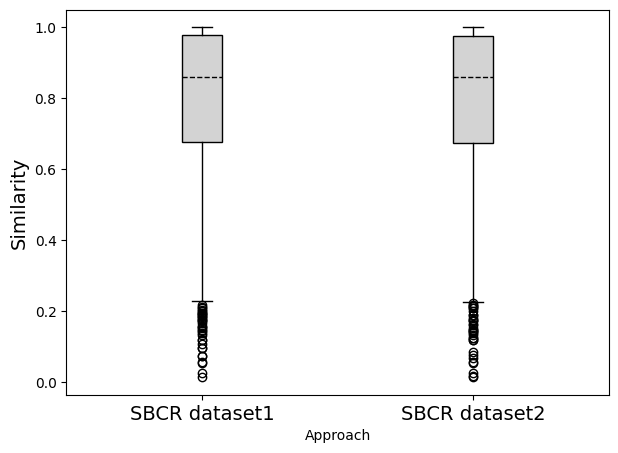

In [8]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_sbcr_clean['sim_sbcr_ds1'], df_sbcr_clean['sim_sbcr_ds2']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=True)

plt.xlabel('Approach')
plt.ylabel('Similarity', fontsize=14)
plt.xticks([1, 2], ['SBCR dataset1', 'SBCR dataset2'], fontsize=14)

# plt.savefig('RQ3_boxplots.png', dpi=300) 
plt.show()  

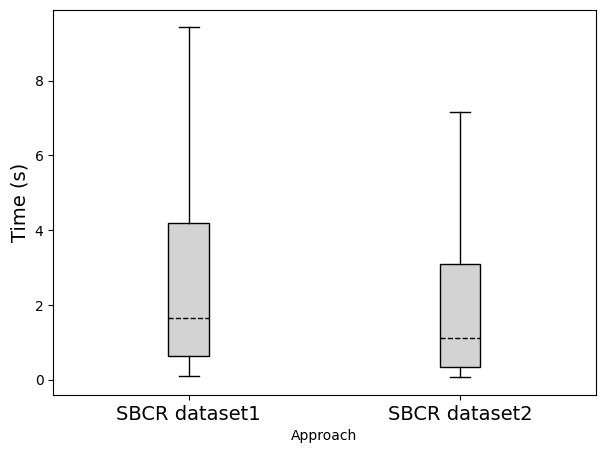

In [9]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_sbcr_clean['time_sbcr_ds1'], df_sbcr_clean['time_sbcr_ds2']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=False)

plt.xlabel('Approach')
plt.ylabel('Time (s)', fontsize=14)
plt.xticks([1, 2], ['SBCR dataset1', 'SBCR dataset2'], fontsize=14)

# plt.savefig('RQ3_boxplots.png', dpi=300) 
plt.show()  

### MergeGen trained on Dataset1 vs MergeGen trained on Dataset2_Java

In [10]:
df_complete = pd.read_json(DATASET2_COMPLETE)

In [11]:
df_mergegen_ds1 = pd.read_csv(MERGEGEN_DATASET1)
data = []
for index, row in df_mergegen_ds1.iterrows():
    chunk = df_complete.iloc[row['chunk_index']]
    chunk_id = f"{chunk['merge_id']}-{chunk['chunk_number']}"
    data.append(chunk_id)
df_mergegen_ds1['chunk_id'] = data
df_mergegen_ds1 = df_mergegen_ds1.rename(columns={"complete_similarity": "sim_mergegen", "time": "time_mergegen", "similarity":"sim_mergegen_trunc", "parents_similarity":"mergegen_parents_sim"})
df_mergegen_ds1.sort_values('chunk_id')

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim,result,chunk_id
4829,34189,1.000000,1.000000,0.115168,1.000000,0.885906,0.942953,SUCCEED,100004-3
177,8621,0.000000,0.000000,0.415754,0.000000,0.256410,0.128205,FAIL,100013-1
1587,8622,0.825397,0.830508,0.153938,0.830508,0.000000,0.415254,FAIL,100013-2
3547,9605,1.000000,1.000000,0.293847,0.000000,1.000000,0.500000,SUCCEED,100084-1
2350,58390,0.636364,0.642857,0.115627,0.000000,0.642857,0.321429,FAIL,100103-2
...,...,...,...,...,...,...,...,...,...
2286,63285,0.862745,0.862745,0.057039,1.000000,0.862745,0.931373,FAIL,99969-148
2346,63177,0.862745,0.862745,0.057800,1.000000,0.862745,0.931373,FAIL,99969-22
3921,63191,1.000000,1.000000,0.382698,0.837416,0.985263,0.911340,SUCCEED,99969-52
7,63201,0.862745,0.862745,0.057588,1.000000,0.862745,0.931373,FAIL,99969-62


In [12]:
df_mergegen_ds2 = pd.read_csv(MERGEGEN_DATASET2)
data = []
for index, row in df_mergegen_ds2.iterrows():
    chunk = df_complete.iloc[row['chunk_index']]
    chunk_id = f"{chunk['merge_id']}-{chunk['chunk_number']}"
    data.append(chunk_id)
df_mergegen_ds2['chunk_id'] = data
df_mergegen_ds2 = df_mergegen_ds2.rename(columns={"complete_similarity": "sim_mergegen", "time": "time_mergegen", "similarity":"sim_mergegen_trunc", "parents_similarity":"mergegen_parents_sim"})
df_mergegen_ds2.sort_values('chunk_id')

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim,result,chunk_id
4170,34189,1.000000,1.000000,0.118333,1.000000,0.885906,0.942953,SUCCEED,100004-3
2321,8621,1.000000,1.000000,0.389742,1.000000,0.000000,0.500000,SUCCEED,100013-1
4262,8622,1.000000,1.000000,0.160315,1.000000,0.000000,0.500000,SUCCEED,100013-2
2442,9605,1.000000,1.000000,0.311668,0.000000,1.000000,0.500000,SUCCEED,100084-1
1509,58390,0.636364,0.642857,0.113700,0.000000,0.642857,0.321429,FAIL,100103-2
...,...,...,...,...,...,...,...,...,...
5221,63285,1.000000,1.000000,0.072279,0.862745,1.000000,0.931373,SUCCEED,99969-148
5283,63177,1.000000,1.000000,0.073499,0.862745,1.000000,0.931373,SUCCEED,99969-22
2932,63191,1.000000,1.000000,0.397662,0.837416,0.985263,0.911340,SUCCEED,99969-52
2102,63201,1.000000,1.000000,0.073540,0.862745,1.000000,0.931373,SUCCEED,99969-62


In [13]:
df_mergegen = df_mergegen_ds1.merge(df_mergegen_ds2, on='chunk_id', suffixes=('_ds1', '_ds2'))
df_mergegen

,chunk_index_ds1,sim_mergegen_trunc_ds1,sim_mergegen_ds1,time_mergegen_ds1,v1_similarity_ds1,v2_similarity_ds1,mergegen_parents_sim_ds1,result_ds1,chunk_id,chunk_index_ds2,sim_mergegen_trunc_ds2,sim_mergegen_ds2,time_mergegen_ds2,v1_similarity_ds2,v2_similarity_ds2,mergegen_parents_sim_ds2,result_ds2
0,59484,0.000000,0.000000,1.289259,0.356476,0.755187,0.555831,FAIL,228576-22,59484,0.000000,0.000000,1.323704,0.242101,0.810920,0.526510,FAIL
1,1491,0.980392,0.958333,0.064080,0.958333,1.000000,0.979167,FAIL,214661-2,1491,0.980392,0.958333,0.065673,0.958333,1.000000,0.979167,FAIL
2,27472,0.000000,0.000000,0.652215,0.146982,0.000000,0.073491,FAIL,190323-10,27472,0.000000,0.000000,0.624698,0.910688,0.000000,0.455344,FAIL
3,44031,0.639344,0.620690,0.131144,0.696629,0.635294,0.665962,FAIL,267141-1,44031,0.639344,0.620690,0.132782,0.696629,0.635294,0.665962,FAIL
4,36386,0.684685,0.693878,0.070638,0.500000,1.000000,0.750000,FAIL,267569-7,36386,1.000000,1.000000,0.126571,0.638298,0.693878,0.666088,SUCCEED
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6570,20687,1.000000,1.000000,0.178132,0.416938,1.000000,0.708469,SUCCEED,247986-2,20687,1.000000,1.000000,0.185633,0.416938,1.000000,0.708469,SUCCEED
6571,36418,1.000000,1.000000,0.395311,0.880000,0.349776,0.614888,SUCCEED,167007-1,36418,0.775120,0.783383,0.414093,0.877076,0.455357,0.666217,FAIL
6572,17318,0.634731,0.588179,1.299691,0.589303,0.477345,0.533324,SUCCEED,251982-2,17318,0.642424,0.574427,1.345178,0.572658,0.370607,0.471632,SUCCEED
6573,45321,1.000000,1.000000,0.235969,1.000000,0.691667,0.845833,SUCCEED,192296-2,45321,1.000000,1.000000,0.242553,1.000000,0.691667,0.845833,SUCCEED


In [14]:
df_mergegen_clean = df_mergegen.dropna(subset=['sim_mergegen_ds1', 'sim_mergegen_ds2'])
df_mergegen_clean

,chunk_index_ds1,sim_mergegen_trunc_ds1,sim_mergegen_ds1,time_mergegen_ds1,v1_similarity_ds1,v2_similarity_ds1,mergegen_parents_sim_ds1,result_ds1,chunk_id,chunk_index_ds2,sim_mergegen_trunc_ds2,sim_mergegen_ds2,time_mergegen_ds2,v1_similarity_ds2,v2_similarity_ds2,mergegen_parents_sim_ds2,result_ds2
0,59484,0.000000,0.000000,1.289259,0.356476,0.755187,0.555831,FAIL,228576-22,59484,0.000000,0.000000,1.323704,0.242101,0.810920,0.526510,FAIL
1,1491,0.980392,0.958333,0.064080,0.958333,1.000000,0.979167,FAIL,214661-2,1491,0.980392,0.958333,0.065673,0.958333,1.000000,0.979167,FAIL
2,27472,0.000000,0.000000,0.652215,0.146982,0.000000,0.073491,FAIL,190323-10,27472,0.000000,0.000000,0.624698,0.910688,0.000000,0.455344,FAIL
3,44031,0.639344,0.620690,0.131144,0.696629,0.635294,0.665962,FAIL,267141-1,44031,0.639344,0.620690,0.132782,0.696629,0.635294,0.665962,FAIL
4,36386,0.684685,0.693878,0.070638,0.500000,1.000000,0.750000,FAIL,267569-7,36386,1.000000,1.000000,0.126571,0.638298,0.693878,0.666088,SUCCEED
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6570,20687,1.000000,1.000000,0.178132,0.416938,1.000000,0.708469,SUCCEED,247986-2,20687,1.000000,1.000000,0.185633,0.416938,1.000000,0.708469,SUCCEED
6571,36418,1.000000,1.000000,0.395311,0.880000,0.349776,0.614888,SUCCEED,167007-1,36418,0.775120,0.783383,0.414093,0.877076,0.455357,0.666217,FAIL
6572,17318,0.634731,0.588179,1.299691,0.589303,0.477345,0.533324,SUCCEED,251982-2,17318,0.642424,0.574427,1.345178,0.572658,0.370607,0.471632,SUCCEED
6573,45321,1.000000,1.000000,0.235969,1.000000,0.691667,0.845833,SUCCEED,192296-2,45321,1.000000,1.000000,0.242553,1.000000,0.691667,0.845833,SUCCEED


In [15]:
print(df_mergegen_clean[['sim_mergegen_ds1', 'sim_mergegen_ds2', 'time_mergegen_ds1', 'time_mergegen_ds2']].describe())

       sim_mergegen_ds1  sim_mergegen_ds2  time_mergegen_ds1  \
count       6575.000000       6575.000000        6575.000000   
mean           0.768112          0.852850           0.438781   
std            0.328972          0.270466           0.385246   
min            0.000000          0.000000           0.032257   
25%            0.658718          0.827860           0.167182   
50%            0.949416          1.000000           0.288150   
75%            1.000000          1.000000           0.535000   
max            1.000000          1.000000           1.704255   

       time_mergegen_ds2  
count        6575.000000  
mean            0.475611  
std             0.410566  
min             0.038898  
25%             0.187059  
50%             0.314019  
75%             0.586968  
max             1.402251  


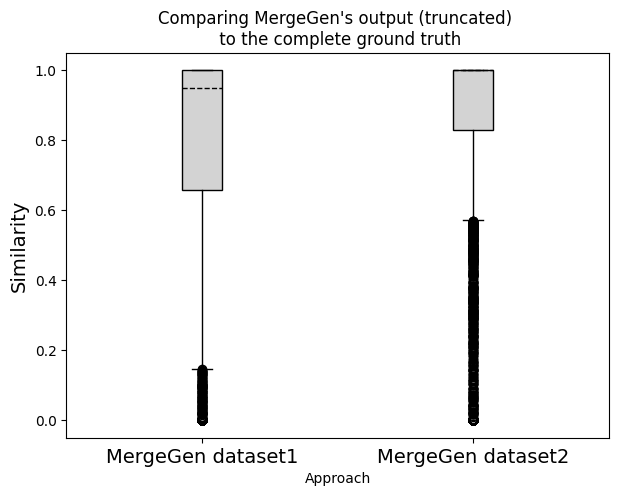

In [16]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_mergegen_clean['sim_mergegen_ds1'], df_mergegen_clean['sim_mergegen_ds2']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=True)
plt.title("Comparing MergeGen's output (truncated) \n to the complete ground truth")
plt.xlabel('Approach')
plt.ylabel('Similarity', fontsize=14)
plt.xticks([1, 2], ['MergeGen dataset1', 'MergeGen dataset2'], fontsize=14)

# plt.savefig('RQ3_boxplots.png', dpi=300) 
plt.show()  

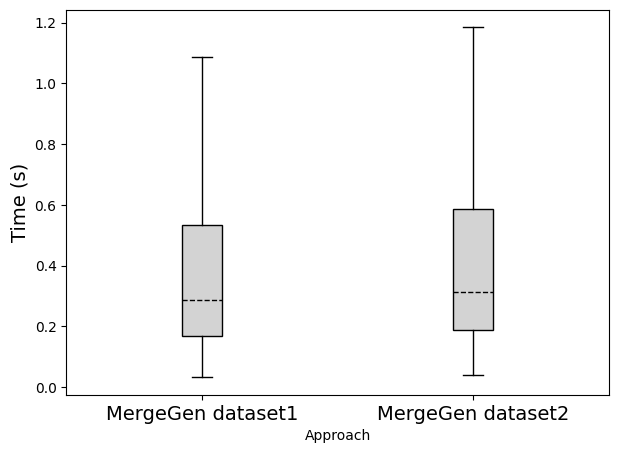

In [17]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_mergegen_clean['time_mergegen_ds1'], df_mergegen_clean['time_mergegen_ds2']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=False)
plt.xlabel('Approach')
plt.ylabel('Time (s)', fontsize=14)
plt.xticks([1, 2], ['MergeGen dataset1', 'MergeGen dataset2'], fontsize=14)

# plt.savefig('RQ3_boxplots.png', dpi=300) 
plt.show()  

### SBCR trained on Dataset2_Java vs MergeGen trained on Dataset2_Java


In [18]:
df_both = df_sbcr_clean.merge(df_mergegen_clean, on='chunk_id')
df_both

,chunk_id,fitness_sbcr_ds1,sim_sbcr_ds1,status_ds1,time_sbcr_ds1,fitness_sbcr_ds2,sim_sbcr_ds2,status_ds2,time_sbcr_ds2,chunk_index_ds1,...,mergegen_parents_sim_ds1,result_ds1,chunk_index_ds2,sim_mergegen_trunc_ds2,sim_mergegen_ds2,time_mergegen_ds2,v1_similarity_ds2,v2_similarity_ds2,mergegen_parents_sim_ds2,result_ds2
0,247633-11,0.772002,0.413502,ok,0.243860,0.772002,0.413502,ok,0.195323,37554,...,0.589247,SUCCEED,37554,1.000000,1.000000,0.098506,0.645161,0.533333,0.589247,SUCCEED
1,218430-3,0.947421,1.000000,ok,1.524886,0.947421,1.000000,ok,0.825038,59863,...,0.939097,SUCCEED,59863,1.000000,1.000000,0.190504,0.951724,0.926471,0.939097,SUCCEED
2,64045-1,0.979891,0.981432,ok,0.996221,0.979891,0.981432,ok,2.291695,5235,...,0.979356,SUCCEED,5235,1.000000,1.000000,0.299400,0.980519,0.978193,0.979356,SUCCEED
3,276497-1,0.841141,0.947891,ok,2.646000,0.844135,1.000000,ok,0.300525,28978,...,0.838726,SUCCEED,28978,1.000000,0.984456,0.360160,0.709030,0.968421,0.838726,SUCCEED
4,228270-4,0.744453,0.822816,ok,0.810900,0.741226,0.818408,ok,0.874901,19428,...,0.723848,SUCCEED,19428,0.891473,1.000000,1.350036,0.607460,0.840237,0.723848,SUCCEED
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1962,258478-4,0.978499,0.980562,ok,2.600460,0.978495,1.000000,ok,1.557349,35832,...,0.977431,SUCCEED,35832,1.000000,1.000000,0.380552,0.976253,0.978610,0.977431,SUCCEED
1963,167370-1,0.676818,0.500189,ok,9.943668,0.688285,0.506004,ok,10.421561,17374,...,0.615597,FAIL,17374,0.666105,0.711382,1.345684,0.488923,0.719258,0.604090,FAIL
1964,91740-2,0.795016,0.793651,ok,4.012038,0.795016,0.793651,ok,2.451555,55023,...,0.788434,FAIL,55023,0.692308,0.696629,0.246882,0.645833,0.931034,0.788434,FAIL
1965,136898-33,0.968318,0.955372,ok,0.580410,0.968289,0.991394,ok,0.611825,39157,...,0.982399,SUCCEED,39157,1.000000,1.000000,0.545362,0.990050,0.974747,0.982399,SUCCEED


In [19]:
print(df_both[['sim_sbcr_ds2', 'sim_mergegen_ds2', 'time_sbcr_ds2', 'time_mergegen_ds2']].describe())

       sim_sbcr_ds2  sim_mergegen_ds2  time_sbcr_ds2  time_mergegen_ds2
count   1967.000000       1967.000000    1967.000000        1967.000000
mean       0.795490          0.893023       4.032866           0.492146
std        0.207495          0.204414       9.825651           0.398674
min        0.013072          0.000000       0.064151           0.039297
25%        0.673640          0.866018       0.327095           0.215865
50%        0.858323          1.000000       1.102100           0.335696
75%        0.973958          1.000000       3.085528           0.599878
max        1.000000          1.000000     186.743766           1.402251


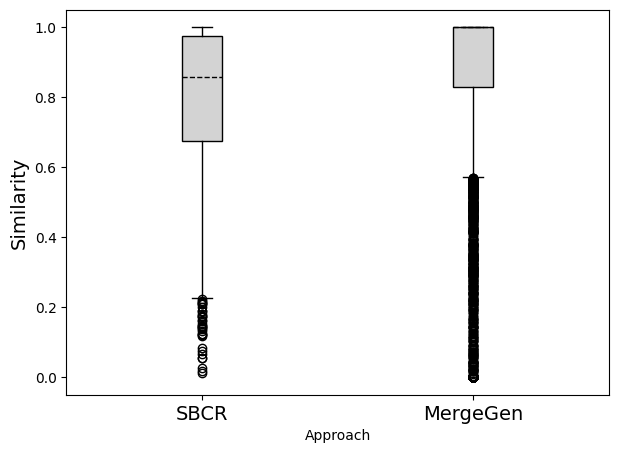

In [20]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_both['sim_sbcr_ds2'], df_mergegen_clean['sim_mergegen_ds2']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=True)

plt.xlabel('Approach')
plt.ylabel('Similarity', fontsize=14)
plt.xticks([1, 2], ['SBCR', 'MergeGen'], fontsize=14)

# plt.savefig('RQ3_boxplots.png', dpi=300) 
plt.show()  

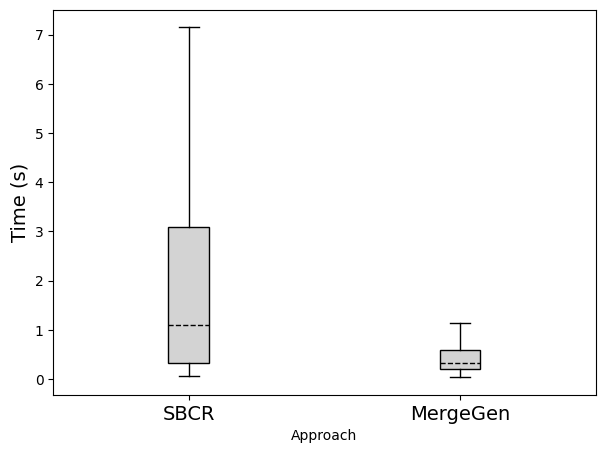

In [21]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_both['time_sbcr_ds2'], df_both['time_mergegen_ds2']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=False)
plt.xlabel('Approach')
plt.ylabel('Time (s)', fontsize=14)
plt.xticks([1, 2], ['SBCR', 'MergeGen'], fontsize=14)

# plt.savefig('RQ3_boxplots.png', dpi=300) 
plt.show()  